# **Bellman Equation and MPD Value & Policy Iteration for Funded Account Modelling**

## Toy Example

### 1) Introduction

$$V(s) = \max_a \mathbb{E}[R + \gamma V(s')]$$

We will be using a Markov Decision Process (MDP) as the core mathematical framework for model sequential decision-making in this project. To better understand how formal MDP is applied in the prop firm setting, we will first begin by using a toy scenario:

A token on a ladder of dollar states {0, 1, 2, 3, 4}. States 0 and 4 are absorbing (game over --> win or lose). From any interior state we pick one of two actions each round:
- Tight: +1 with prob 0.7, -1 with prob 0.3
- Wide: +2 with prob 0.4, -1 with prob 0.6

A win is achieved by reaching 4; and a loss is at 0. (This is essentially the funded account in miniature: 0 = breach, 4 = payout, Tight/Wide = low/high RR)
We now formalize this toy problem as an MDP:
A MDP is formally a five-tuple $$(S, A, P, R, \gamma)$$
- $S$: The set of states
- $A$: The set of actions
- ${P(s' | s, a)}$: Transition kernel: Probability of landing in $s$ given you are in $s$ and take $a$
- $R(s,a)$: Reward
- $ \gamma$: Discount factor

### 2) Step 1 - Toy Example Initialization

The five-tuple in the toy example is defined exactly as:
- $S$: {0, 1, 2, 3, 4}
- $A$: {Tight, Wide}
- ${P(s' | s, a)}$: Transition kernel: Probability of landing in $s$ given you are in $s$ and take $a$
- $R(s,a)$: 1 for reaching 4
- $ \gamma$: 1, we don't discount the toy scenario

$$P(s' \mid s=2,\ \text{Tight}) = \begin{cases} 0.7 & s'=3 \\ 0.3 & s'=1 \end{cases}$$

$$P(s' \mid s=2,\ \text{Wide}) = \begin{cases} 0.4 & s'=4 \\ 0.6 & s'=1 \end{cases}$$

In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

In [1]:
STATES     = [0, 1, 2, 3, 4]
INTERIOR   = [1, 2, 3]         
WIN_STATE, LOSE_STATE = 4, 0
ACTIONS    = ["Tight", "Wide"]
GAMMA      = 1.0
BOUNDARY_VALUE = {LOSE_STATE: 0.0, WIN_STATE: 1.0}   # V(0)=0, V(4)=1

MOVES = {                      
    "Tight": [(0.7, +1), (0.3, -1)],
    "Wide":  [(0.4, +2), (0.6, -1)],
}

def reward(state, action):
    return 0.0                   # payoff lives in the boundary values

def _clamp(landing):
    if landing >= WIN_STATE:  return WIN_STATE     # reach OR exceed target => win
    if landing <= LOSE_STATE: return LOSE_STATE    # reach OR pass floor  => loss
    return landing

def transitions(state, action):
    """P(s'|s,a) as a list of (prob, next_state)."""
    merged = {}
    for prob, step in MOVES[action]:
        s2 = _clamp(state + step)
        merged[s2] = merged.get(s2, 0.0) + prob
    return [(p, s2) for s2, p in merged.items()]

# verify kernels match your hand math
for s in INTERIOR:
    for a in ACTIONS:
        br = transitions(s, a)
        assert abs(sum(p for p,_ in br) - 1.0) < 1e-9
        print(f"state {s}, {a:5s}: {br}")

state 1, Tight: [(0.7, 2), (0.3, 0)]
state 1, Wide : [(0.4, 3), (0.6, 0)]
state 2, Tight: [(0.7, 3), (0.3, 1)]
state 2, Wide : [(0.4, 4), (0.6, 1)]
state 3, Tight: [(0.7, 4), (0.3, 2)]
state 3, Wide : [(0.4, 4), (0.6, 2)]


### 3) Step 2 - The MDP tuple: Physics vs. Objective

| MDP object | Category | Toy ladder | When Relating to Prop firm |
|---|---|---|---|
| $\mathcal{S}$ (states) | Physics (the world) | position on $\{0,1,2,3,4\}$ | account state $(x, m, \ell, k)$: equity, running peak, lock flag, withdrawals taken |
| $\mathcal{A}$ (actions) | Physics (the world) | $\{\text{Tight}, \text{Wide}\}$ | $(r, \rho, w)$: risk size, reward ratio (RR), withdraw-or-push |
| $P(s' \mid s,a)$ (transitions) | Physics (the world) | Tight/Wide kernels ($0.7/0.3$, $0.4/0.6$) | empirical, cost-adjusted return distribution $\mathcal{D}_\rho$: where a trade takes you, and where the edge lives |
| $R(s,a)$ (reward) | Objective (what we care about) | $1$ for reaching $4$ | cash withdrawn (extraction), or $1$ for recouping the budget (survival) |
| $\gamma$ (discount) | Objective (what we care about) | $1$ (no time-preference) | $\beta < 1$: time-value of money plus hazard of losing the account |

Note: The "floor" of a funded account does not get its own MDP object, it is part of $S$, through the running peak $m$, and enforces itself as an absorbing boundary condition on $P$ (breach = the killed state). The barrier isn't an additional constraint, it is a property of the state space and transitions. 

### 4) Step 3 - Markov Property

A process $\{s_t\}$ is Markov if for all $t$,

$$\Pr\big(s_{t+1} \mid s_t, s_{t-1}, \dots, s_0, a_t\big) = \Pr\big(s_{t+1} \mid s_t, a_t\big).$$

Conditioning on the full history gives the same distribution as conditioning on the current state alone. Once you know $s_t$, earlier states add **nothing** about $s_{t+1}$. This is what lets us write the kernel as $P(s' \mid s, a)$ instead of $P(s' \mid s_0, \dots, s_t, a)$. **The next state depends only on the current state, not on the path that led there**.


Whether the property holds depends on what goes in the state. A variable belongs in the state when $P$ or $R$ depends on it and the other state variables don't already capture it.

With equity $x$ alone, it fails. The floor is $F = m - D$, which depends on the peak $m = \max_{\tau \le t} x_\tau$, a function of the whole path. Two histories can reach the same $x$ with different $m$:

$$x_t = 2000,\ m_t = 2000 \Rightarrow F = 0 \qquad \text{vs.} \qquad x_t = 2000,\ m_t = 4000 \Rightarrow F = 2000.$$

Same equity, different breach distance, different next-step probabilities. So $\Pr(s_{t+1} \mid x_t, a_t)$ is not well-defined.

The fix is to put the path-dependent quantities into the state:

$$s_t = (x_t, m_t, \ell_t, k_t).$$

$m_t$ makes the floor a function of the state, $k_t$ makes the payout cap and forced conversion a function of the state, and $\ell_t$ carries lock status. Everything the next transition needs is now computable from $s_t$, so the process is Markov.

Test: given only $s$ with all history hidden, are the next-step probabilities determined? No with equity alone (floor unknown). Yes with $(x, m, \ell, k)$.

### 5) Grading a Fixed Policy

$$V^\pi(s) = \mathbb{E}\big[\, R_0 + \gamma R_1 + \gamma^2 R_2 + \cdots \,\big]$$

where $R_0 = R(s, \pi(s))$ is the reward on this step and $R_1, R_2, ...$ are the rewards on future steps, all under $\pi$

Derivations:

$$(\gamma R_1 + \gamma^2 R_2 + + \gamma^3 R_3 + \cdots)  = \gamma (R_1 + \gamma R_2 + \gamma R_1 + \cdots)$$

We can see the $R_0$ term drops off and now $V^\pi$ is evaluated at the next state, the one in which we land right after taking a step from $s$. When $R_1$ is the next reward to be collected, we are standing at $s'$, and the discounted sum from there $R_1 + \gamma R_2 + \cdots$ is the value of $s'$. Hence the tail is $\gamma V^\pi(s')$

From $s$ under action $\pi(s)$, we don't land in a fixed $s'$, we land in a random one, distributed by the kernel $P(s' | s, \pi(s))$, hence the tail is for the average of $\gamma V^\pi (s')$ over where we might land.

Now, the discounted averaged value of the next state is estimated by:

$$V^\pi(s) = R(s,\pi(s)) + \gamma \sum_{s'} P\big(s'\mid s,\pi(s)\big)\, V^\pi(s')$$

Which is the **Bellman expectation equation**




### 6) Grading a Fixed Policy - Toy Example

Fix the policy Tight at every state. Tight's kernel: $+1$ with probability $0.7$, $-1$ with probability $0.3$. Boundaries $V(0) = 0$, $V(4) = 1$.

The Bellman expectation equation at each interior state:

$$V^\pi(1) = 0.7\,V^\pi(2) + 0.3\,V^\pi(0) = 0.7\,V^\pi(2)$$
$$V^\pi(2) = 0.7\,V^\pi(3) + 0.3\,V^\pi(1)$$
$$V^\pi(3) = 0.7\,V^\pi(4) + 0.3\,V^\pi(2) = 0.7 + 0.3\,V^\pi(2)$$

Substitute $V^\pi(1)$ and $V^\pi(3)$ into the middle equation:

$$V^\pi(2) = 0.7\,(0.7 + 0.3\,V^\pi(2)) + 0.3\,(0.7\,V^\pi(2))$$
$$V^\pi(2) = 0.49 + 0.21\,V^\pi(2) + 0.21\,V^\pi(2)$$
$$0.58\,V^\pi(2) = 0.49$$
$$V^\pi(2) = 0.845$$

Back-substitute:

$$V^\pi(1) = 0.592, \qquad V^\pi(2) = 0.845, \qquad V^\pi(3) = 0.954$$

In [4]:
def bellman_backup_expectation(state, action, V):
    r = reward(state, action)                          # R(s,a)
    expected_next = 0.0
    for prob, next_state in transitions(state, action):
        expected_next += prob * V[next_state]          # sum P(s'|s,a) V(s')
    return r + GAMMA * expected_next                   # R + gamma * sum

def evaluate_policy(policy, tol=1e-12, max_sweeps=10_000, verbose=False):
    V = {s: 0.0 for s in INTERIOR}
    V.update(BOUNDARY_VALUE)                           # pin boundaries
    for sweep in range(max_sweeps):
        delta, newV = 0.0, dict(V)                     # snapshot => synchronous update
        for s in INTERIOR:
            newV[s] = bellman_backup_expectation(s, policy[s], V)
            delta = max(delta, abs(newV[s] - V[s]))
        V = newV
        if verbose and sweep < 3:
            print(f"  sweep {sweep+1}: " + "  ".join(f"V({s})={V[s]:.4f}" for s in INTERIOR))
        if delta < tol:
            break
    return V

tight = {s: "Tight" for s in INTERIOR}
V = evaluate_policy(tight, verbose=True)
print("\nTight-everywhere values:", {s: round(V[s],4) for s in INTERIOR})
print("Hand check (Part II):     V(1)=0.592  V(2)=0.845  V(3)=0.954")

  sweep 1: V(1)=0.0000  V(2)=0.0000  V(3)=0.7000
  sweep 2: V(1)=0.0000  V(2)=0.4900  V(3)=0.7000
  sweep 3: V(1)=0.3430  V(2)=0.4900  V(3)=0.8470

Tight-everywhere values: {1: 0.5914, 2: 0.8448, 3: 0.9534}
Hand check (Part II):     V(1)=0.592  V(2)=0.845  V(3)=0.954


### 7) From Grading to Choosing

$$Q^\pi(s,a) = R(s,a) + \gamma \sum_{s'} P(s'\mid s,a)\, V^\pi(s')$$

The action value $Q^\pi(s,a)$ is the worth of taking action $a$ right now at state $s$, then following the current policy afterward. The only difference from the Bellman expectation equation is that $a$ is a free input, not fixed by $\pi$.

$$Q(2,\text{Tight}) = 0.7\,V(3) + 0.3\,V(1) = 0.846$$
$$Q(2,\text{Wide}) = 0.4\,V(4) + 0.6\,V(1) = 0.755$$

Tight wins at state 2 by about 9 percentage points. But if the max at state 1 or 3 tells us to switch either to Wide, the values were computed under the old policy and are now stale, so we regrade and repeat. That alternation is **policy iteration**:

$$\pi_0 \xrightarrow{\text{evaluate}} V^{\pi_0} \xrightarrow{\text{improve}} \pi_1 \xrightarrow{\text{evaluate}} V^{\pi_1} \xrightarrow{\text{improve}} \pi_2 \cdots$$

The output is not a number, it is a map from each state to its optimal action. When that map is non-uniform (i.e. Tight at some states, Wide at others), we have the state-dependent risk geometry the prop-firm solver exists to compute. "Where is each account, and what should it do next?" becomes a lookup into that map.

In [5]:
def value_iteration(tol=1e-12, max_sweeps=10_000, verbose=False):
    V = {s: 0.0 for s in INTERIOR}; V.update(BOUNDARY_VALUE)
    policy = {s: None for s in INTERIOR}
    for sweep in range(max_sweeps):
        delta, newV = 0.0, dict(V)
        for s in INTERIOR:
            q_by_action = [(bellman_backup_expectation(s, a, V), a) for a in ACTIONS]
            best_q, best_a = max(q_by_action)          # max value AND argmax action
            newV[s], policy[s] = best_q, best_a
            delta = max(delta, abs(newV[s] - V[s]))
        V = newV
        if verbose and sweep < 4:
            print(f"  sweep {sweep+1}: " + "  ".join(f"V({s})={V[s]:.3f}[{policy[s]}]" for s in INTERIOR))
        if delta < tol:
            print(f"  converged after {sweep+1} sweeps"); break
    return V, policy

V, policy = value_iteration(verbose=True)
print("\nOPTIMAL policy:", policy)
print("OPTIMAL values:", {s: round(V[s],4) for s in INTERIOR})

  sweep 1: V(1)=0.000[Wide]  V(2)=0.400[Wide]  V(3)=0.700[Tight]
  sweep 2: V(1)=0.280[Wide]  V(2)=0.490[Tight]  V(3)=0.820[Tight]
  sweep 3: V(1)=0.343[Tight]  V(2)=0.658[Tight]  V(3)=0.847[Tight]
  sweep 4: V(1)=0.461[Tight]  V(2)=0.696[Tight]  V(3)=0.897[Tight]
  converged after 63 sweeps

OPTIMAL policy: {1: 'Tight', 2: 'Tight', 3: 'Tight'}
OPTIMAL values: {1: 0.5914, 2: 0.8448, 3: 0.9534}


In [7]:
def improve_policy(V):
    policy = {}
    for s in INTERIOR:
        _, best_a = max((bellman_backup_expectation(s, a, V), a) for a in ACTIONS)
        policy[s] = best_a
    return policy

def policy_iteration(init_action="Wide", verbose=False):
    policy = {s: init_action for s in INTERIOR}
    for r in range(1, 100):
        V = evaluate_policy(policy)          # grade exactly (Step 2)
        new_policy = improve_policy(V)       # greedy improve (Step 3 logic)
        if verbose:
            print(f"  round {r}: " + "  ".join(f"{s}:{new_policy[s]}" for s in INTERIOR) + f"   V(2)={V[2]:.4f}")
        if new_policy == policy:
            print(f"  STABLE after {r} rounds, pi* found"); return V, policy
        policy = new_policy
    return V, policy

Vpi, pi = policy_iteration(init_action="Wide", verbose=True)
print("\nBoth solvers agree:", pi == policy)

  round 1: 1:Tight  2:Tight  3:Tight   V(2)=0.5794
  round 2: 1:Tight  2:Tight  3:Tight   V(2)=0.8448
  STABLE after 2 rounds, pi* found

Both solvers agree: True


### 8) Backward Induction 

The Bellman update at a state needs the values of its downstream states, the ones it can transition to. For a one-directional coordinate, "downstream" always means further along in that one direction. So if we solve in the order end → start, then by the time we reach any state, everything it can move to is already behind us, already computed. Every update uses known numbers, no iteration. This concept is defined as backward induction.

This is where the prop-firm problem differs from the fair-coin toy. In the coin example, state 2's downstream includes state 3, but state 3's downstream includes state 2: each is downstream of the other, so the graph has a cycle.

> Backward induction works exactly when the transition graph has no cycles — a DAG (directed acyclic graph). Then a valid solving order, the reverse topological order, always exists.

The withdrawal counter $k$ gives the prop-firm problem that structure: $k$ only climbs, so no state at level $k$ is reachable from level $k+1$. The levels stack, and we solve them top-down.

The real problem mixes coordinates of both kinds, so the solver nests the two algorithms, each doing the job its structure allows:

| Coordinate | Direction | Treatment |
|---|---|---|
| $k$ (withdrawals) | up only, few discrete levels | backward induction, outer loop |
| $\ell$ (lock flag) | $0 \to 1$ only | backward induction, outer loop |
| $m$ (running peak) | up only, but continuous | part of the 2-D grid, not a clean outer loop |
| $x$ (equity) | up and down (cyclic) | value / policy iteration on the grid |

Two of these are important. 

$m$ never decreases. It is a running maximum, and $m' = \max(m, x') \ge m$ always. A withdrawal lowers the balance but does not un-happen the high. So $m$ is acyclic like $k$ — but unlike $k$ it is continuous and coupled to $x$. It is a full continuous axis that happens to move one way, and it lives inside the grid.

The floor is what makes $m$ matter. Pre-lock the floor is $m - \$2000$, so as $m$ ratchets up, the barrier itself is dragged upward. This is the trailing-drawdown barrier — a boundary that is not fixed but pulled along by our running maximum.


## Funded Account Modelling via Bellman Equation and Backward Induction

### Background

A futures proprietary trading firm sells trading products called **Evaluations**. The trader pays a one-time fee and trades a simulated account under the firm's rules. Reaching a profit target without breaking a loss limit earns a funded account, from which the trader can continue to trade and attempt to withdraw most of the profit. For the trader this works like buying an option: the loss per attempt is capped at the fee, while payouts can be several times larger. 

Firms and plans differ mainly in how the loss limit behaves (static, trailing intraday, trailing at the end of day), whether it stops trailing, and what a payout requires: daily loss limits, consistency rules, minimum profitable days, caps, and profit split. 

The earlier toy model, a $0 to $4 ladder with a Tight and a Wide action, showed that the best action depends on the distance to each boundary. The funded account is the same problem with
realistic parts:

| Firm rule | Toy model | Funded model |
|---|---|---|
| loss limit | absorbing state at $0 | breach, worth 0 |
| payout level | absorbing state at $4 | payout, worth 1 |
| trade target | Tight or Wide | RR from 1.0 to 5.0 |
| trade outcomes | two-point coin | 884 empirical trades per RR (2026 only for example) |
| trailing limit that locks | none | peak added to the state, then a hand-off to a fixed-floor stage |
| repeated payouts and fees | none | a renewal cycle giving $ per day |

Each rule changes the structure of the problem, not just its inputs. Choosing another firm or **Evaluation** / **Funded** plan means changing these elements while the solvers stay the same.

### Risk and target selection for a prop-firm funded account

The subsequent sections of the notebook models a Lucid Pro 25K funded account as a Markov decision process. Before the account's peak balance reaches $26,100, the loss limit trails $1,000 below the peak. And it freezes at $25,100, and a payout of $1,000 can be taken at $27,100 for example.

Using 884 trades from an intraday NQ strategy (January to September 2026), the model finds the reward-to-risk target that maximizes the chance of a payout in each account state. It then
measures how long accounts last and converts both into expected profit per day for five accounts trading in rotation.



In [9]:
import os, sys
FUNDED = r"C:\Users\2115h\Desktop\Trading\Propfirm Convex Analysis\Funded"
os.chdir(FUNDED)                  # so relative paths like "ledgers.pkl" resolve
sys.path.insert(0, FUNDED)        # so Python can find Postlock.py, Prelock.py, ...

In [10]:
%load_ext autoreload
%autoreload 2
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import Postlock as post, Prelock as pre, Lifecycle as life, Sweep

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### 1) Trade data

Each trade is measured in R, the loss at the 25-point stop. At each RR target, a trade either hits the target (+RR), hits the stop (-1), or times out after 60 minutes **at whatever it shows**. The table gives the average result per trade at each target. 

In [11]:
pd.DataFrame({
    "RR": list(post.Coins),
    "edge_R": [sum(p * r for p, r in c) for c in post.Coins.values()],
    "distinct_outcomes": [len(c) for c in post.Coins.values()],
}).round(4)

,RR,edge_R,distinct_outcomes
0,1.00,0.0553,4
1,1.25,0.0646,4
2,1.50,0.0620,5
3,2.00,0.0268,11
4,2.50,0.0543,17
5,3.00,0.0736,25
6,3.50,0.0921,30
7,4.00,0.1250,39
8,4.50,0.1328,48
9,5.00,0.1055,59


### 2) Account rules

All amounts below are measured from the $25,000 starting balance.

| Level | Balance | Meaning |
|---|---|---|
| +2,100 | $27,100 | Max payout: withdraw $1,000 |
| +1,100 | $26,100 | peak that locks the floor |
| +100 | $25,100 | floor after the lock |
| 0 | $25,000 | start |
| −1,000 | $24,000 | starting floor, trails $1,000 below the peak |

The account takes one trade per day, so the floor updating after each trade matches the
firm's end-of-day rule. The problem splits into two stages. Pre-lock has a moving floor,
post-lock a fixed one.

### 3) Post-lock stage


Once locked, the state is just the equity x. The value V(x) is the probability of reaching $27,100 before $25,100. It satisfies the Bellman optimality equation

$$V(x) = \max_{RR} \sum_{x'} P(x' \mid x, RR)\, V(x'),$$

with V = 1 at the payout and V = 0 at the floor. Equity is kept on a $50 grid, and a trade landing between two grid points is split between them in proportion to its distance.

converged after 289 sweeps


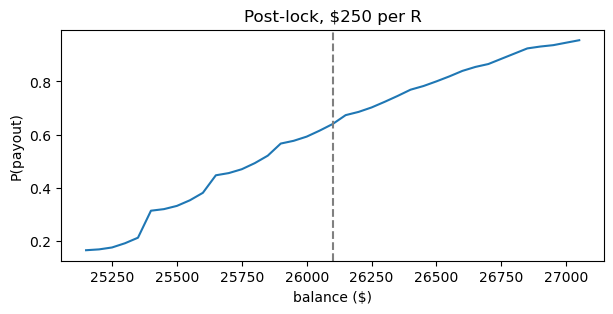

P(payout | just locked at $26,100) = 0.6401, using example $250 per R


In [13]:
V_post, pol_post = post.solve_post(post.Coins, post.risk)
i_entry = post.cell_index(post.Entry, post.Floor, post.Dx)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(25_000 + post.grid, V_post)
ax.axvline(25_000 + post.Entry, ls="--", color="grey")
ax.set(xlabel="balance ($)", ylabel="P(payout)", title=f"Post-lock, ${post.risk} per R")
plt.show()
print(f"P(payout | just locked at $26,100) = {V_post[i_entry]:.4f}, using example $250 per R")

### 4) Pre-lock stage

Before the lock the floor trails the peak, so the state needs two numbers: the peak m and the
drawdown below it, y. A trade ends in one of four ways: a breach (y reaches $1,000), a lock
(the peak reaches $1,100), a new peak (y resets to 0), or a deeper or shallower drawdown under
the same peak. A lock hands the account to the post-lock stage, so the value of locking at x'
is the post-lock value V_post(x').

converged after 167 sweeps


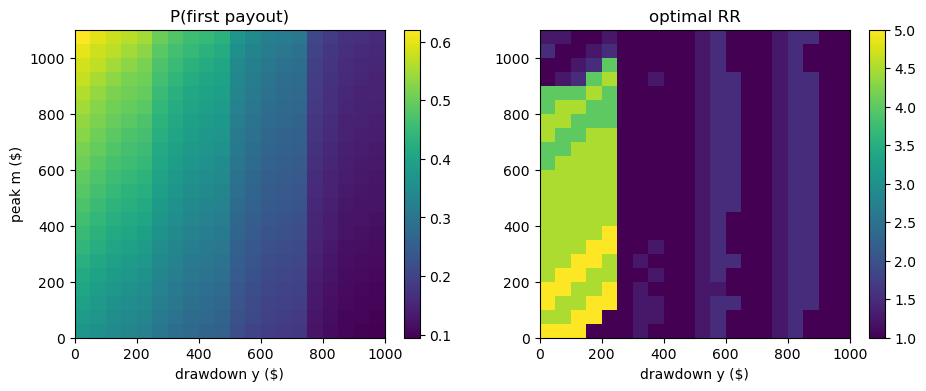

P(first payout | fresh funded account) = 0.3733


In [14]:
V_pre, pol_pre = pre.solve_pre_fast(pre.Coins, V_post)
extent = [0, pre.DD_limit, 0, pre.Lock_peak]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im = axes[0].imshow(V_pre, origin="lower", aspect="auto", extent=extent)
axes[0].set(title="P(first payout)", xlabel="drawdown y ($)", ylabel="peak m ($)")
fig.colorbar(im, ax=axes[0])
im = axes[1].imshow(pol_pre.astype(float), origin="lower", aspect="auto", extent=extent, cmap="viridis")
axes[1].set(title="optimal RR", xlabel="drawdown y ($)")
fig.colorbar(im, ax=axes[1])
plt.show()
print(f"P(first payout | fresh funded account) = {V_pre[0, 0]:.4f}")

### 5) Validation

Two fair-coin cases have exact answers. Post-lock with one-cell steps is the gambler's ruin,
and the expected number of trades from the lock entry is 20 × 20 = 400. Pre-lock locks with
probability (20/21)^22, because each new high must be reached before a $1,000 drawdown.
Matching both checks the transition logic, the handoff, and the time calculation.

In [15]:
fair = {1.0: [(0.5, 1.0), (0.5, -1.0)]}
T_fair = post.expected_trades_post(fair, {i: 1.0 for i in range(len(post.grid))}, risk=post.Dx)
V_fair = pre.evaluate_policy_pre_fast(pre.fixed_policy(1.0), fair, None, risk=50, lock_one=True)
print(f"post-lock fair-coin duration: {T_fair[i_entry]:.2f}   exact 400")
print(f"pre-lock fair-coin P(lock):   {V_fair[0, 0]:.6f}   exact {(20/21)**22:.6f}")

post-lock fair-coin duration: 400.00   exact 400
pre-lock fair-coin P(lock):   0.341850   exact 0.341850


### 6) Does choosing RR by state help?

The optimal policy changes RR with the account's state. To check that this is not fitted
noise, the policy is built on the first 442 trades and scored on the last 442, and then the
other way around. Post-lock is re-solved on each half as well, so nothing from the test half
leaks into the policy.

In [16]:
half = len(post.RETURN_ARRAYS[1.0]) // 2
halves = {name: {r: post.collapse_to_coin(a[sl]) for r, a in post.RETURN_ARRAYS.items()}
          for name, sl in [("A", slice(None, half)), ("B", slice(half, None))]}
vpost = {k: post.solve_post(c, post.risk)[0] for k, c in halves.items()}

rows = []
for build, test in [("A", "B"), ("B", "A")]:
    _, policy = pre.solve_pre_fast(halves[build], vpost[build])
    score = lambda pol: pre.evaluate_policy_pre_fast(pol, halves[test], vpost[test])[0, 0]
    rows.append(dict(built_on=build, scored_on=test, built_policy=score(policy),
                     always_rr_1=score(pre.fixed_policy(1.0)),
                     always_rr_5=score(pre.fixed_policy(5.0))))
pd.DataFrame(rows).round(4)


converged after 226 sweeps
converged after 290 sweeps
converged after 151 sweeps
converged after 171 sweeps


,built_on,scored_on,built_policy,always_rr_1,always_rr_5
0,A,B,0.3507,0.2976,0.2908
1,B,A,0.3898,0.3013,0.3354


> **重要 Finding — Out-of-Sample Validation**
>
> Despite the limited sample of 884 trades, selecting the reward-to-risk ratio by account state improves funded-account survival in both swapped out-of-sample tests. This suggests the improvement is not limited to a single train/test split.